In [1]:
# ============================================================
# Imports, Setup, and Data Loading
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set visual style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

# --- RELATIVE FILE PATHS ---
current_dir = os.getcwd()
BASE_DIR = os.path.abspath(os.path.join(current_dir, '..'))
PREPARED_DIR = os.path.join(BASE_DIR, 'prepared_data')
clean_data_path = os.path.join(PREPARED_DIR, 'clean_data.csv')

# Load the cleaned data from Notebook 1
df = pd.read_csv(clean_data_path)

print(f"Data loaded successfully from: {clean_data_path}")
print(f"Shape: {df.shape}")

Data loaded successfully from: C:\Users\bktsh\OneDrive - Botswana Accountancy College\R&I project and analysis\Student Career Success Prediction new project dataset 2\prepared_data\clean_data.csv
Shape: (50000, 30)


C:\Users\bktsh\AppData\Local\Temp\ipykernel_25296\4012674444.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rate_programme.values, y=rate_programme.index, palette='viridis')


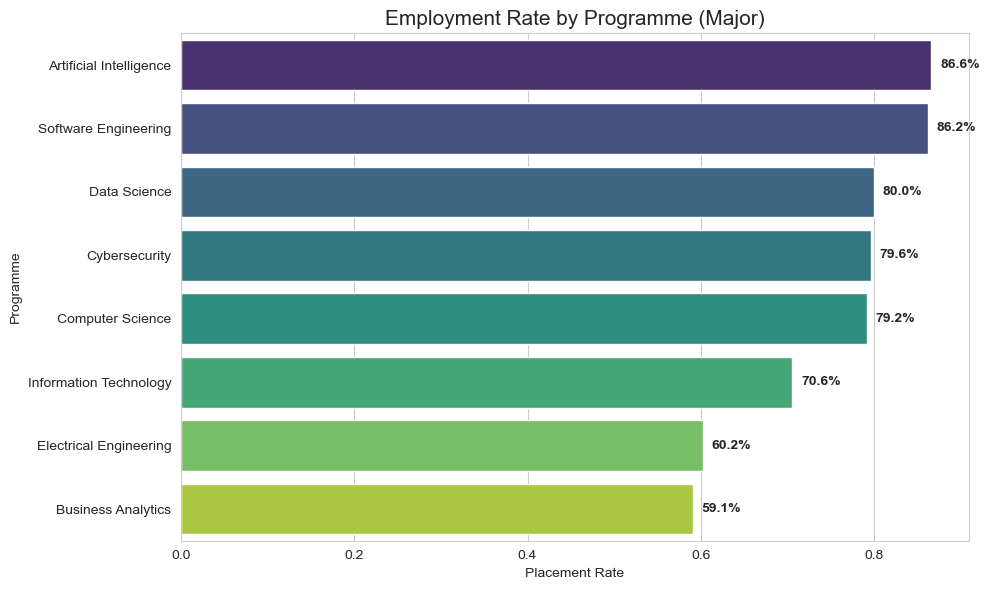

In [2]:
# ============================================================
# Categorical Variables vs. Target (Programme/Major)
# ============================================================
plt.figure(figsize=(10, 6))

# Note: The dataset calls this 'Major', but your supervisor calls it 'Programme'
rate_programme = df.groupby('Major')['placement_status_binary'].mean().sort_values(ascending=False)

sns.barplot(x=rate_programme.values, y=rate_programme.index, palette='viridis')
plt.title('Employment Rate by Programme (Major)', fontsize=15)
plt.xlabel('Placement Rate')
plt.ylabel('Programme')
for i, v in enumerate(rate_programme.values):
    plt.text(v + 0.01, i, f"{v:.1%}", va='center', fontweight='bold')
plt.tight_layout()
plt.show()

C:\Users\bktsh\AppData\Local\Temp\ipykernel_25296\2060984345.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rate_gender.index, y=rate_gender.values, palette='Set2')


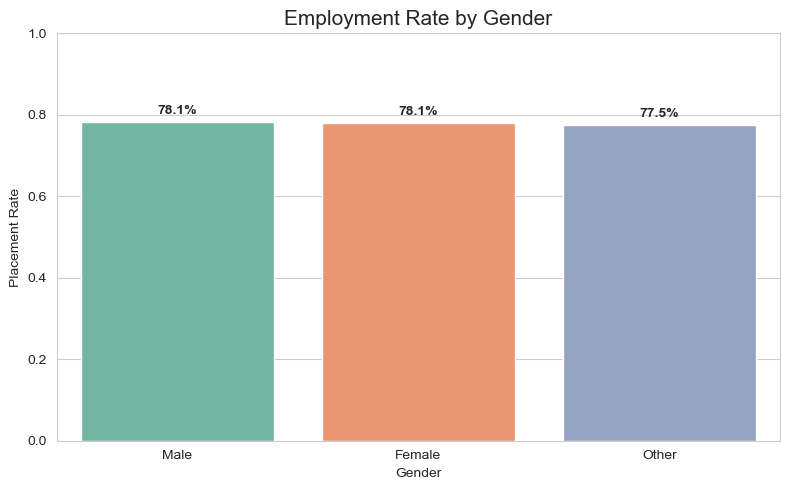

In [3]:
# ============================================================
# Employment Rate by Gender
# ============================================================
plt.figure(figsize=(8, 5))
rate_gender = df.groupby('Gender')['placement_status_binary'].mean().sort_values(ascending=False)

sns.barplot(x=rate_gender.index, y=rate_gender.values, palette='Set2')
plt.title('Employment Rate by Gender', fontsize=15)
plt.ylabel('Placement Rate')
plt.ylim(0, 1)
for i, v in enumerate(rate_gender.values):
    plt.text(i, v + 0.02, f"{v:.1%}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

C:\Users\bktsh\AppData\Local\Temp\ipykernel_25296\1022078001.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rate_year.index, y=rate_year.values, palette='Blues')


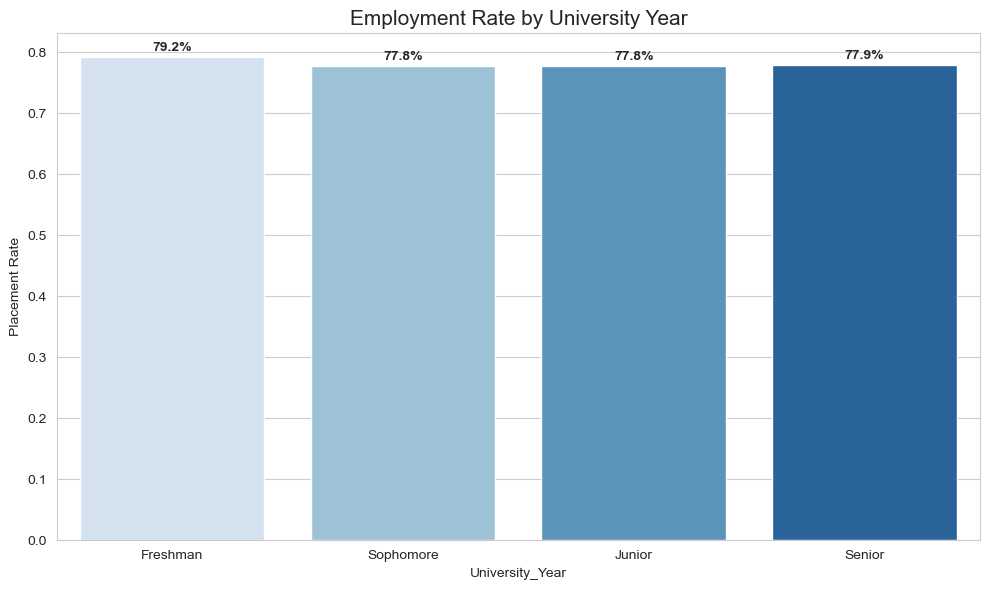

In [4]:
# ============================================================
# Employment Rate by University Year (Cohort)
# ============================================================
plt.figure(figsize=(10, 6))
# Ensuring the order is Freshman -> Sophomore -> Junior -> Senior
year_order = ['Freshman', 'Sophomore', 'Junior', 'Senior']
rate_year = df.groupby('University_Year')['placement_status_binary'].mean().reindex(year_order)

sns.barplot(x=rate_year.index, y=rate_year.values, palette='Blues')
plt.title('Employment Rate by University Year', fontsize=15)
plt.ylabel('Placement Rate')
for i, v in enumerate(rate_year.values):
    plt.text(i, v + 0.01, f"{v:.1%}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

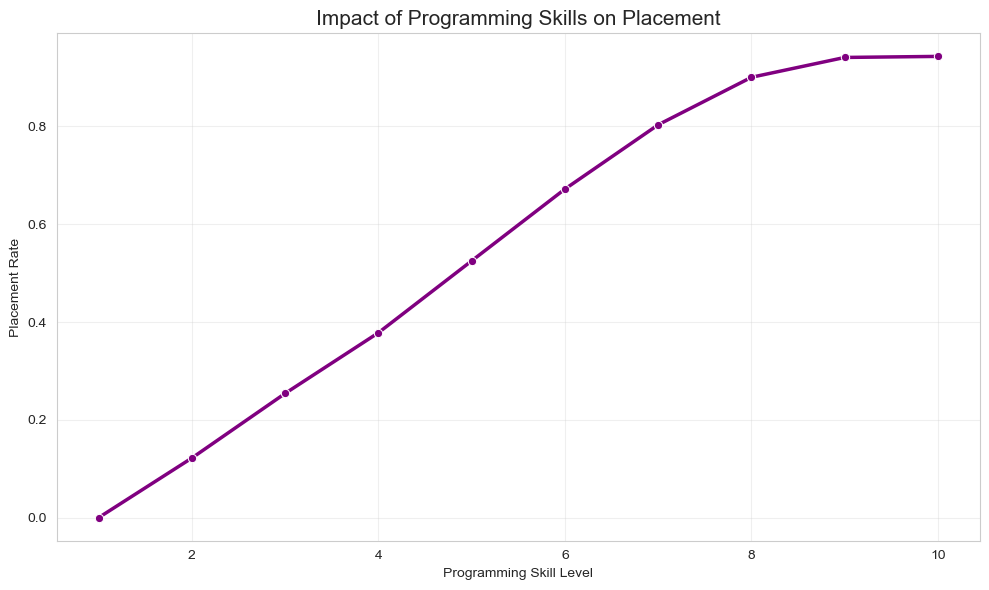

In [5]:
# ============================================================
# Impact of Programming Skills on Placement
# ============================================================
plt.figure(figsize=(10, 6))
rate_skills = df.groupby('Programming_Skill')['placement_status_binary'].mean()

sns.lineplot(x=rate_skills.index, y=rate_skills.values, marker='o', color='purple', linewidth=2.5)
plt.title('Impact of Programming Skills on Placement', fontsize=15)
plt.xlabel('Programming Skill Level')
plt.ylabel('Placement Rate')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\bktsh\AppData\Local\Temp\ipykernel_25296\1563671804.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Internships', y='placement_status_binary', data=df, ax=axes[0], palette='magma', errorbar=None)
C:\Users\bktsh\AppData\Local\Temp\ipykernel_25296\1563671804.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Programming_Skill', y='placement_status_binary', data=df, ax=axes[1], palette='crest', errorbar=None)
C:\Users\bktsh\AppData\Local\Temp\ipykernel_25296\1563671804.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=

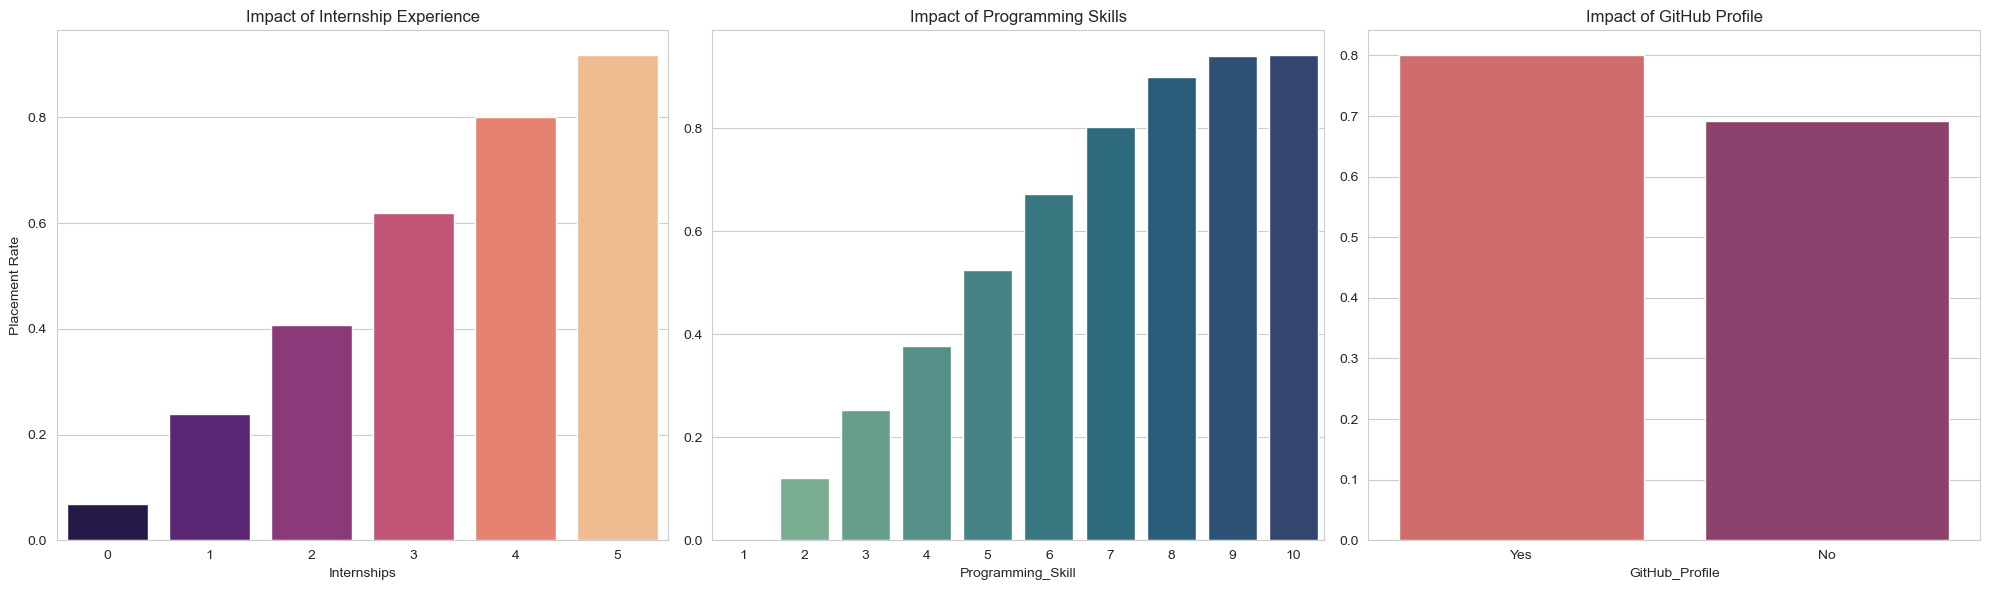

In [6]:
# ============================================================
# Skills, Experience, and Placement (Side-by-Side)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Internship Experience
sns.barplot(x='Internships', y='placement_status_binary', data=df, ax=axes[0], palette='magma', errorbar=None)
axes[0].set_title('Impact of Internship Experience')
axes[0].set_ylabel('Placement Rate')

# 2. Programming Skills
sns.barplot(x='Programming_Skill', y='placement_status_binary', data=df, ax=axes[1], palette='crest', errorbar=None)
axes[1].set_title('Impact of Programming Skills')
axes[1].set_ylabel('')

# 3. GitHub Profile
sns.barplot(x='GitHub_Profile', y='placement_status_binary', data=df, ax=axes[2], palette='flare', errorbar=None)
axes[2].set_title('Impact of GitHub Profile')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

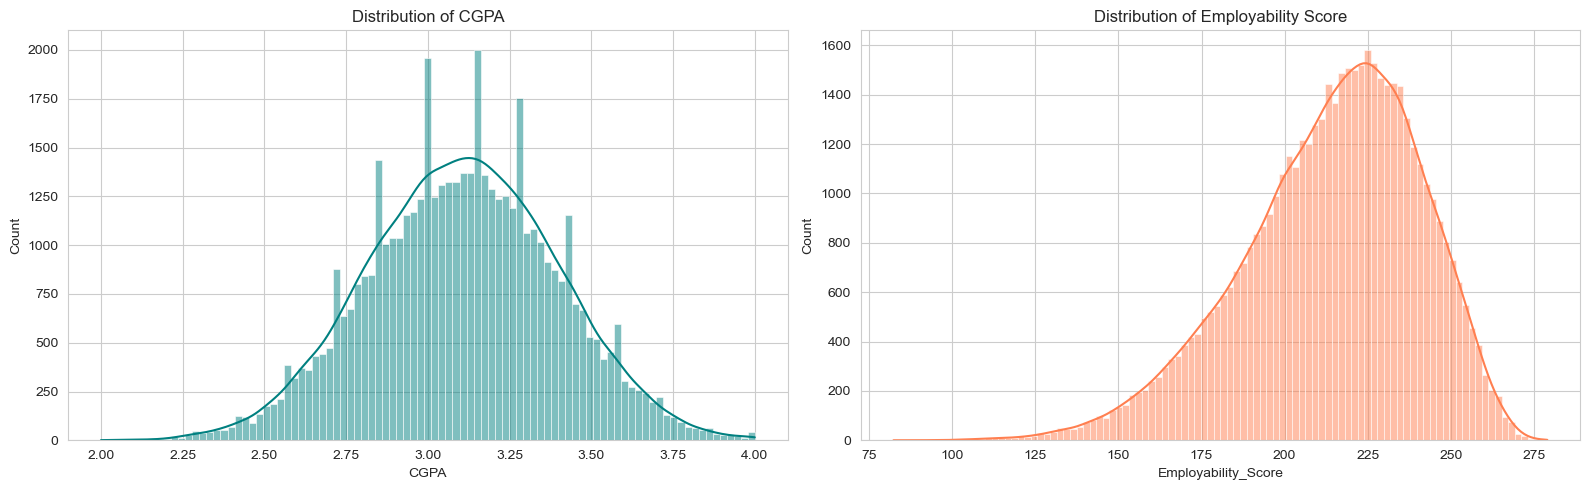

In [7]:
# ============================================================
# Univariate Analysis (Numeric Distributions)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(df['CGPA'], kde=True, ax=axes[0], color='teal')
axes[0].set_title('Distribution of CGPA')

sns.histplot(df['Employability_Score'], kde=True, ax=axes[1], color='coral')
axes[1].set_title('Distribution of Employability Score')

plt.tight_layout()
plt.show()

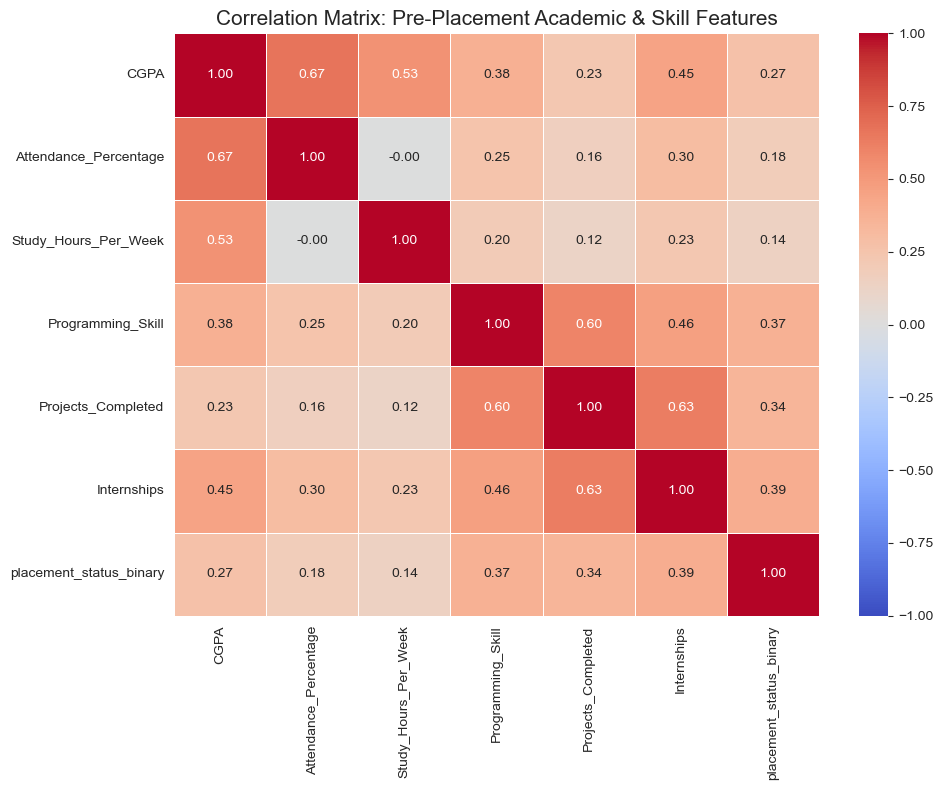

In [8]:
# ============================================================
# Correlation Matrix (Pre-Placement Features Only)
# ============================================================
# We MUST exclude Resume_Score, Interview_Score, and Employability_Score 
# because they are recorded DURING or AFTER the placement process (Target Leakage).
# We only look at what the university knows BEFORE the student applies.

corr_cols = [
    'CGPA', 
    'Attendance_Percentage', 
    'Study_Hours_Per_Week',
    'Programming_Skill', 
    'Projects_Completed',
    'Internships',
    'placement_status_binary'
]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix: Pre-Placement Academic & Skill Features', fontsize=15)
plt.tight_layout()
plt.show()

C:\Users\bktsh\AppData\Local\Temp\ipykernel_25296\38983026.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Communication_Skills', y='placement_status_binary', data=df, ax=axes[0, 0], palette='Blues', errorbar=None)
C:\Users\bktsh\AppData\Local\Temp\ipykernel_25296\38983026.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Teamwork', y='placement_status_binary', data=df, ax=axes[0, 1], palette='Greens', errorbar=None)
C:\Users\bktsh\AppData\Local\Temp\ipykernel_25296\38983026.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x

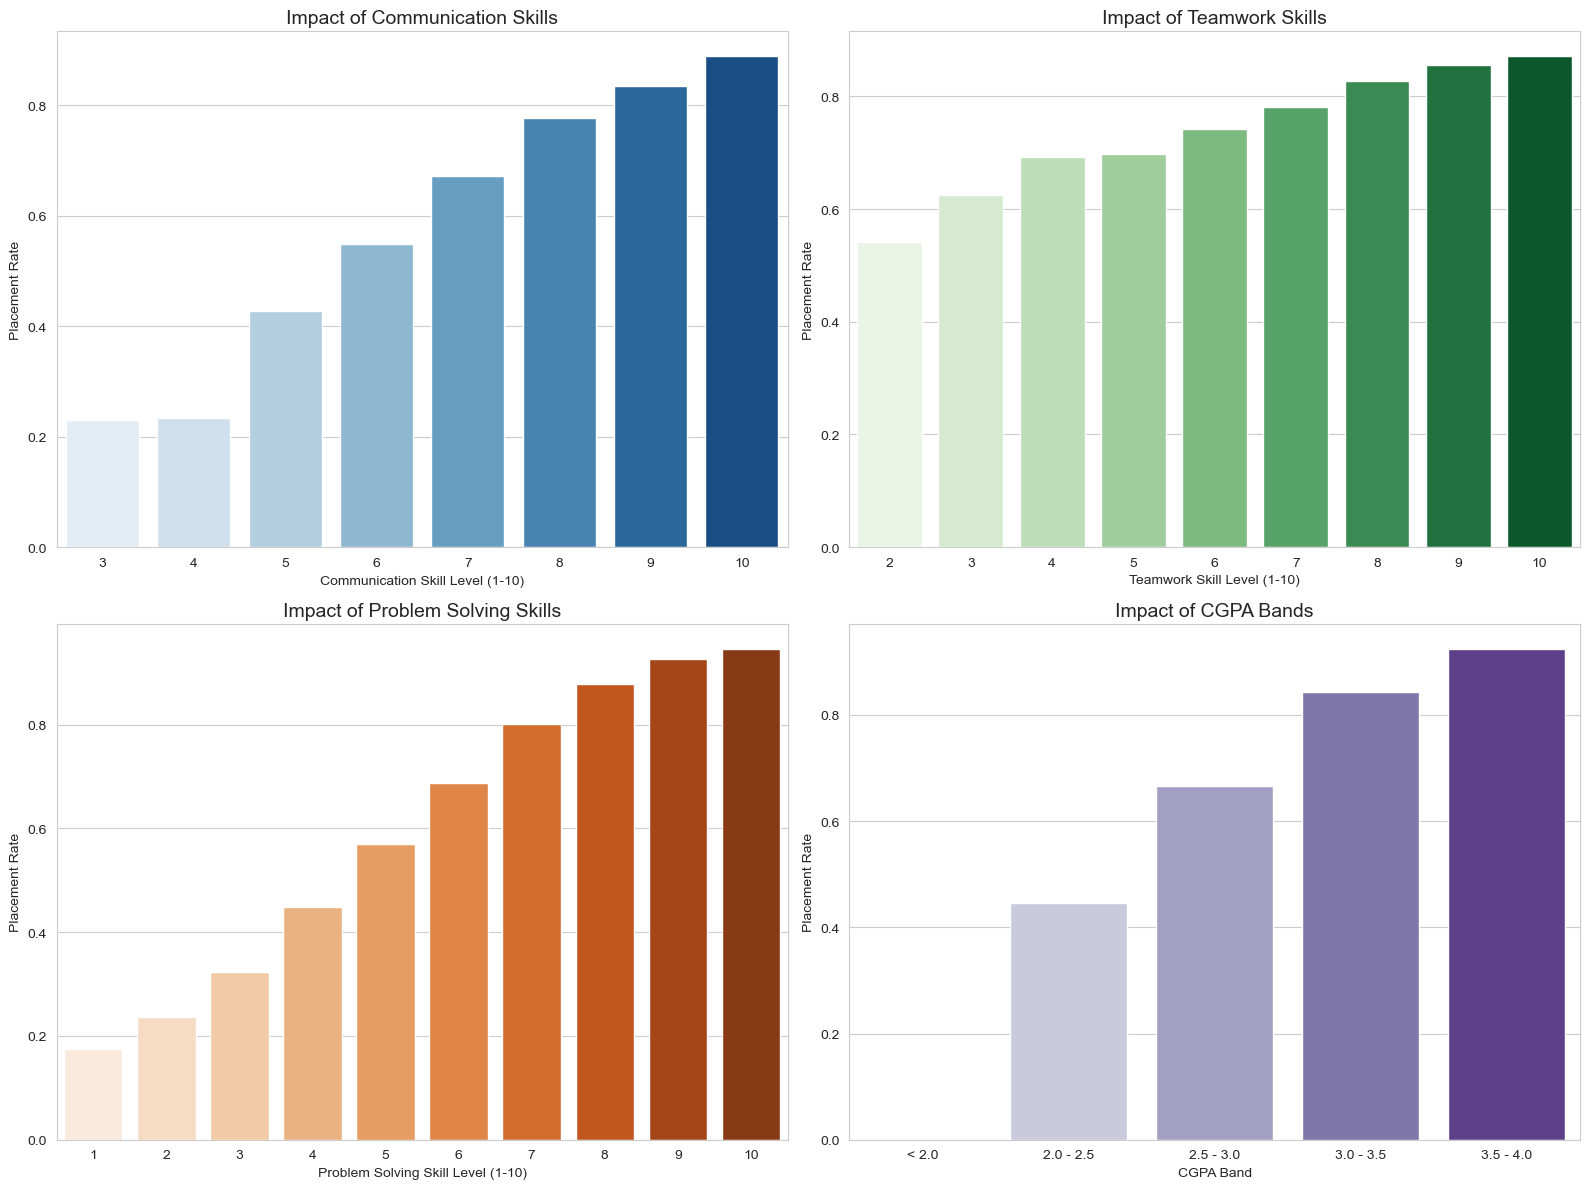

In [9]:
# ============================================================
# Additional Skills & Academic Analysis (Soft Skills + CGPA)
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Communication Skills
sns.barplot(x='Communication_Skills', y='placement_status_binary', data=df, ax=axes[0, 0], palette='Blues', errorbar=None)
axes[0, 0].set_title('Impact of Communication Skills', fontsize=14)
axes[0, 0].set_ylabel('Placement Rate')
axes[0, 0].set_xlabel('Communication Skill Level (1-10)')

# 2. Teamwork
sns.barplot(x='Teamwork', y='placement_status_binary', data=df, ax=axes[0, 1], palette='Greens', errorbar=None)
axes[0, 1].set_title('Impact of Teamwork Skills', fontsize=14)
axes[0, 1].set_ylabel('Placement Rate')
axes[0, 1].set_xlabel('Teamwork Skill Level (1-10)')

# 3. Problem Solving
sns.barplot(x='Problem_Solving', y='placement_status_binary', data=df, ax=axes[1, 0], palette='Oranges', errorbar=None)
axes[1, 0].set_title('Impact of Problem Solving Skills', fontsize=14)
axes[1, 0].set_ylabel('Placement Rate')
axes[1, 0].set_xlabel('Problem Solving Skill Level (1-10)')

# 4. CGPA (Grouped into bands for a cleaner bar chart)
# Creating a temporary column for CGPA bands to avoid the messy scatter plot
df['CGPA_Band'] = pd.cut(df['CGPA'], bins=[0, 2.0, 2.5, 3.0, 3.5, 4.0], 
                         labels=['< 2.0', '2.0 - 2.5', '2.5 - 3.0', '3.0 - 3.5', '3.5 - 4.0'])
sns.barplot(x='CGPA_Band', y='placement_status_binary', data=df, ax=axes[1, 1], palette='Purples', errorbar=None)
axes[1, 1].set_title('Impact of CGPA Bands', fontsize=14)
axes[1, 1].set_ylabel('Placement Rate')
axes[1, 1].set_xlabel('CGPA Band')

plt.tight_layout()
plt.show()

# Clean up the temporary column
df = df.drop(columns=['CGPA_Band'])

# Notebook 2: Exploratory Data Analysis — Findings Summary

## 1. Univariate Analysis
*   **CGPA:** The distribution of CGPA is roughly normal, centering around 3.0 (on a 4.0 scale). 
*   **Employability Score:** The Employability Score follows a near-perfect normal distribution, centering around 225. *(Note: This feature will be dropped in Notebook 3 due to target leakage).*

## 2. Demographics & Programme Analysis
*   **Gender:** The placement rate is nearly identical across all genders (Male: 78.1%, Female: 78.1%, Other: 77.5%). This indicates that the university's placement process is highly equitable and gender-inclusive.
*   **Programme (Major):** This is a highly predictive categorical variable. Placement rates vary significantly by programme:
    *   **Top Performers:** Artificial Intelligence (86.6%) and Software Engineering (86.2%) have the highest employment rates.
    *   **Mid-Tier:** Data Science (80.0%), Cybersecurity (79.6%), and Computer Science (79.2%) perform consistently above average.
    *   **Lower Performers:** Information Technology (70.6%), Electrical Engineering (60.2%), and Business Analytics (59.1%) have the lowest rates.
*   **University Year:** The placement rate remains virtually flat (77.8% to 79.2%) across Freshmen, Sophomores, Juniors, and Seniors. This implies that students are securing placements consistently throughout their academic journey, not just in their final year.

## 3. Skills & Experience (The Key Drivers)
*   **Internships:** The number of internships completed is a critical predictor. Placement rates scale almost linearly: students with 0 internships have a <10% placement rate, while those with 5 internships approach 90%+.
*   **GitHub Profile:** Having a GitHub profile noticeably increases the placement rate (approx. 80% with a profile vs. 68% without).
*   **Programming Skills (Hard Skill):** This is the strongest technical predictor. Students at levels 1-2 have a near 0% placement rate, while students at levels 8-10 reach a 90%+ placement rate.
*   **Communication Skills:** There is a clear upward trend. Students scoring 3-4 have a ~22% placement rate, which scales dramatically to over 85% for students scoring 9-10. 
*   **Teamwork Skills:** Similar to communication, teamwork shows a strong linear relationship. Students scoring 2-3 hover around 55-62%, while those scoring 9-10 exceed 85%.
*   **Problem Solving:** This soft skill shows the most dramatic curve. Students at level 1 have less than 20% placement, but by level 7 they cross the 80% mark, peaking at nearly 95% for level 10.
*   **CGPA (Academic Performance):** By grouping CGPA into bands, the data reveals a clear step-wise increase. Students with a CGPA between 2.0-2.5 have a ~45% placement rate, which climbs steadily to nearly 90% for students with a 3.5-4.0 CGPA. *(Note: The "< 2.0" band is missing from the chart because no students in the dataset have a CGPA below 2.0).*
*   **Internships (Experience):** The number of internships completed is a critical predictor. Placement rates scale almost linearly: students with 0 internships have a <10% placement rate, while those with 5 internships approach 90%+.
*   **GitHub Profile:** Having a GitHub profile noticeably increases the placement rate (approx. 80% with a profile vs. 68% without). 

**Summary:** The data proves that employability is not driven by a single factor. A student needs a combination of strong academics (CGPA), technical ability (Programming), practical experience (Internships/Projects), and polished soft skills (Communication/Teamwork/Problem Solving) to maximize their chances of placement.

## 4. Correlation Analysis (Pre-Placement Features Only)
*   We intentionally **excluded** `Resume_Score`, `Interview_Score`, and `Employability_Score` from this matrix. These scores are recorded *during or after* the hiring process, meaning they are target leakage and cannot be used for prediction. 
*   Among the valid pre-placement features, the target variable (`placement_status_binary`) has the strongest positive correlations with:
    *   `Internships` (0.39)
    *   `Programming_Skill` (0.37)
    *   `Projects_Completed` (0.34)
    *   `CGPA` (0.27)
*   This confirms our strategy for Notebook 3: the model must rely strictly on academic performance, skills, and extracurriculars that the university can actually influence before a student applies.

## 5. Next Steps
The data is rich and shows clear, actionable trends. We will now proceed to **Notebook 3: Model Training**, where we will drop the leaking features and train our predictive models using only pre-placement data.